## Code structure

- **Imports:** Kör direkt, ingen funktion behövs
- **Data Loading:** Skapa en funktion för att läsa in datasetet
- **EDA and Data Cleaning:** Börja direkt i notebooken (KLAR)
- **Descriptive Statistics:** Börja direkt i notebooken
- **Data Visualization:** Börja direkt i notebooken
- **Simulation:** Funktion om det känns naturligt
- **Confidence Intervals:** Skapa en funktion
- **Hypothesis Testing:** Skapa en funktion
- **Power Analysis (VG):** Skapa en funktion

## Notebook structure

1. Imports
2. Data Loading
3. Exploratory Data Analysis and Data Cleaning
4. Descriptive Statistics
5. Data Visualization
6. Simulation
7. Confidence Intervals
8. Hypothesis Testing
9. Power Analysis (VG)
10. Method Justification (VG)

# Nivå G

### Imports

In [1]:
import pandas as pd         # Hanterar och analyserar tabeller (DataFrames)
import numpy as np          # Utför numeriska beräkningar och hanterar arrayer
import matplotlib.pyplot as plt # Skapar diagram och visualiseringar
from scipy import stats     # Hämtar statistiska funktioner från SciPy
import seaborn as snsb      # Skapar statistiska diagram
import os                   # Hanterar bland annat filer och mappar
import math                 # importerar funktion för matematiska beräkningar
import sys                  # Ger tillgång till Pythons systeminställningar och sökvägar
sys.path.append("..")       # Lägger till mappen ovanför notebooks i Pythons importsökväg

## 1. Descriptive analysis

#### 1.1 tables (summary)

In [2]:
from src.io_utils import load_data 
from src.metrics import summary_statistics

df = load_data("../data/health_study_dataset.csv")
summary = summary_statistics(df)
display(summary)


,age,weight,height,systolic_bp,cholesterol
mean,49.0,73.4,171.8,149.0,4.93
50%,50.0,73.2,171.4,149.0,4.97
min,18.0,33.7,144.4,107.0,2.50
max,90.0,114.4,200.4,186.0,7.88


#### 1.2 Graphs

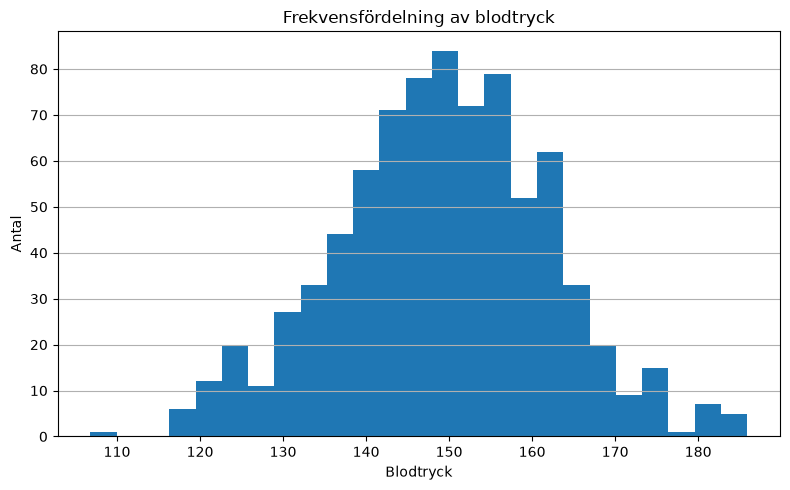

In [3]:
# GRAF 1: HISTOGRAM ÖVER BLODTRYCK
from src.viz import hist

graf1 = hist(df) # anropar funktionen och sparar figuren

# TOLKNING: Diagrammet över frekvensfördelningen visar oss att en stor 
# andel av personerna i urvalet befinner sig mellan spannet 135 - 165, men toppar kring 145-155.

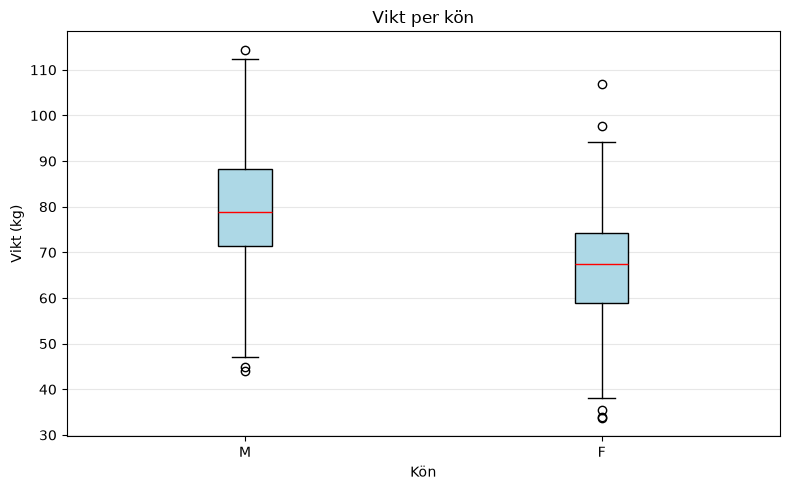

In [4]:
# GRAF 2: LÅDDIAGRAM ÖVER VIKT PER KÖN
from src.viz import box
graf2 = box(df) # anropar funktionen och sparar figuren

# TOLKNING: Diagrammet visar att männen (M) i vårt urval har en högre medianvikt 
# (ca 79 kg) jämfört med kvinnorna (F), där medianvikten är ca 68 kg. 
# För båda könen ryms de centrala 50 % av observationerna (mellan Q1 och Q3) inom lådorna:
# - Män: 50 % av individerna ligger mellan Q1 (ca 71 kg) och Q3 (ca 88 kg).
# - Kvinnor: 50 % av individerna ligger mellan Q1 (ca 59 kg) och Q3 (ca 74 kg).
# Whiskrarna visar spridningen upp till normala yttervärden, och cirklar 
# utanför markerar potentiella extremvärden (outliers) för respektive grupp.

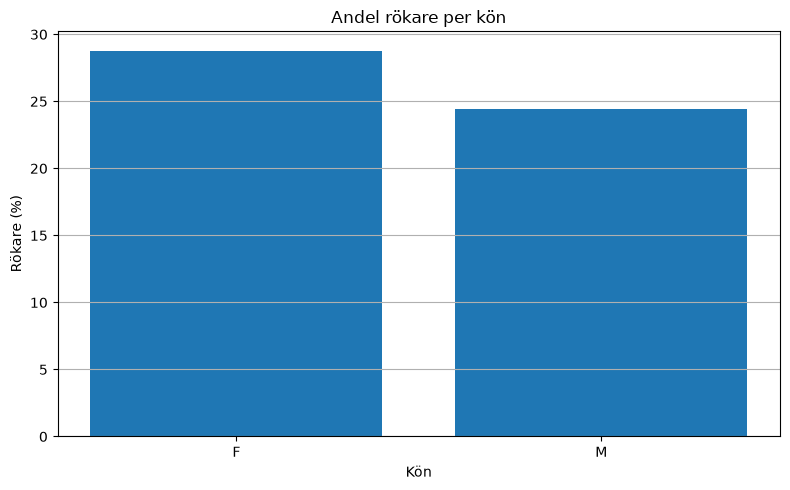

In [5]:
# GRAF 3:STAPELDIAGRAM ÖVER ANDELEN RÖKARE PER KÖN
from src.viz import bar
graf3 = bar(df) # anropar funktionen och sparar figuren

# TOLKNING: Andelen rökare i urvalet är något högre bland kvinnor (F, ca 28–29 %) 
# jämfört med män (M, ca 24 %).

## 2. Case simulation

In [6]:
from src.metrics import simulation
simulation(df)

Antal sjuka i originaldatasetet: 47
Andel sjuka i originaldatasetet: 5.88%
Antal sjuka i simuleringen: 54
Andel sjuka i simuleringen: 5.40%


## 3. Confidence intervals (Normalapproximation)

In [7]:
from src.metrics import konfidensintervall
konfidensintervall(df)

(np.float64(148.29209036025347), np.float64(150.06515963974655))

## 4. Hypothesis testing

In [8]:
from src.hypothesis_testing import hypothesis
hypothesis(df)

'Standard t-test: t = 0.450, p = 0.6527'

### 4.1 Förklaring av resultatet

- T-värde: 0,450. 

Det finns ingen exakt gräns för vad som räknas för ett lågt eller
Ett högt absolut t-värde innebär att skillnaden är stor i förhållande till osäkerheten
Ett lågt absolut t-värde innebär motsatsen
Det finns ingen exakt gräns för vad som räknas som ett högt eller lågt t-värde, men det fniss en grov tumregel:

***Grov tumregel:***
- |t| < 1 = lågt t-värde
- |t| ≈ 2 = börjar ofta ge statistiskt signifikant resultat
- |t| > 2 = kan ge statistiskt signifikant resultat
- |t| > 3 = relativt högt t-värde

I vårt fall fickvi under 1, vilket kan anses vara ett lågt t-värde: skillnaden är alltså liten i förhållande till osäkerheten

- P-värde: 0,6527

P-värdet ligger över signifikansnivån 0,05, vilket innebär att vi inte kan förkasta nollhypotesen.
Nollhypotesen utgår från antagandet att det inte finns någon skillnad mellan gruppernas medelvärden i populationen.
Vi har alltså inte tillräckligt med statistiskt stöd för att säga att rökare har högre medelblodtryck än icke-rökare. Den observerade skillnaden i vårt urval kan bero på slumpmässig variation.

# Nivå VG

## 1. Confidence intervals (Bootstrap)

Källa: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html
Källa: Joakim Lindhs föreläsning om konfidesintervall, med exempele på Bootstrap som funktion. https://hermods.omniway.se/studentcourselessons/33815217 

In [ ]:
from src.metrics import bootstrap, konfidensintervall

print (f"Med boostrapmetoden får i konfidensintervallet {bootstrap(df)}")
print(f"Med normalapproximationen får vi konfidensintervall{konfidensintervall(df)}")

# Med boostrapmetoden får i konfidensintervallet [148.29073437 150.0658875 ]
# Med normalapproximationen får vi konfidensintervall(np.float64(148.29209036025347), np.float64(150.06515963974655))

# TOLKNING
# Metoderna ger nästan identiska resultat och skiljer sig först på tredje decimalen.
# Detta beror på centrala gränsvärdessatsen. När stickprovet är tillräckligt 
# stort (n = 800) blir fördelningen av stickprovets medelvärden normalfördelad. 
# Det gör att den teoretiska normalapproximationen stämmer överens med 
# bootstrap-simuleringen. Normalapproximationen använder en matematisk formel för att
# räkna ut konfidensintervallet på vår färdiga kurva. Bootstrapmetoden bygger kurvan genom
# tusentals stickprov med återläggning, och räknar därefter ut konfidensintervallet genom att skära bort 2,5%
# av resultaten i båda ändarna av kurvan.

Med boostrapmetoden får i konfidensintervallet [148.29073437 150.0658875 ]
Med normalapproximationen får vi konfidensintervall(np.float64(148.29209036025347), np.float64(150.06515963974655))
